# Student Performance Prediction System

Beginner ML project: predict a student's **final score** (regression) and derive a **Pass/Fail** result (score >= 50).

Workflow: Load -> Understand -> Clean -> EDA -> Split -> Train -> Evaluate -> Predict

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score

sns.set_theme(style='whitegrid')
%matplotlib inline

## 1. Load the dataset
The data is synthetic, generated by `src/generate_data.py`.

In [2]:
df = pd.read_csv('../data/student_data.csv')
print('Shape:', df.shape)
df.head()

Shape: (600, 14)


,student_id,gender,age,study_hours_per_week,attendance_percentage,previous_score,sleep_hours,assignments_completed,extracurricular,parental_education,internet_access,health_status,final_score,pass_fail
0,1,Male,20,4.42,81.42,51.58,7.74,9,Yes,NaN,Yes,Good,72.06,1
1,2,Female,17,21.86,80.49,54.74,7.07,7,No,PhD,No,Good,54.94,1
2,3,Female,19,7.08,91.71,56.97,7.29,6,Yes,High School,Yes,Excellent,59.94,1
3,4,Female,17,13.64,64.55,77.85,6.16,3,No,High School,Yes,Good,41.81,0
4,5,Male,20,21.39,NaN,72.73,6.71,4,No,NaN,No,Fair,36.21,0


## 2. Understand the data

In [3]:
df.info()
print('\nMissing values:\n', df.isna().sum())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             600 non-null    int64  
 1   gender                 600 non-null    str    
 2   age                    600 non-null    int64  
 3   study_hours_per_week   570 non-null    float64
 4   attendance_percentage  572 non-null    float64
 5   previous_score         600 non-null    float64
 6   sleep_hours            600 non-null    float64
 7   assignments_completed  600 non-null    int64  
 8   extracurricular        600 non-null    str    
 9   parental_education     569 non-null    str    
 10  internet_access        600 non-null    str    
 11  health_status          600 non-null    str    
 12  final_score            600 non-null    float64
 13  pass_fail              600 non-null    int64  
dtypes: float64(5), int64(4), str(5)
memory usage: 65.8 KB

Missing values

,student_id,age,study_hours_per_week,attendance_percentage,previous_score,sleep_hours,assignments_completed,final_score,pass_fail
count,600.000000,600.000000,570.000000,572.000000,600.00000,600.000000,600.000000,600.000000,600.000000
mean,300.500000,18.510000,14.810211,77.971748,64.19665,6.968900,6.950000,59.170233,0.788333
std,173.349358,1.750717,5.788312,11.534592,14.64399,1.430787,1.918411,11.316595,0.408831
min,1.000000,16.000000,1.000000,43.540000,12.93000,3.000000,2.000000,28.020000,0.000000
25%,150.750000,17.000000,10.785000,70.040000,54.29500,5.997500,6.000000,51.480000,1.000000
50%,300.500000,18.000000,14.870000,78.690000,64.95500,6.900000,7.000000,59.350000,1.000000
75%,450.250000,20.000000,18.577500,86.650000,74.50000,7.980000,8.250000,66.747500,1.000000
max,600.000000,21.000000,32.790000,100.000000,100.00000,11.590000,10.000000,93.560000,1.000000


## 3. Clean the data
Remove duplicates, fill missing numbers with the median and missing categories with the most common value.

In [4]:
df = df.drop_duplicates()
numeric_cols = ['study_hours_per_week','attendance_percentage','previous_score','sleep_hours','assignments_completed','age']
categorical_cols = ['gender','extracurricular','parental_education','internet_access','health_status']
for c in numeric_cols:
    df[c] = df[c].fillna(df[c].median())
for c in categorical_cols:
    df[c] = df[c].fillna(df[c].mode()[0])
print('Missing after cleaning:', df.isna().sum().sum())

Missing after cleaning: 0


## 4. Exploratory data analysis

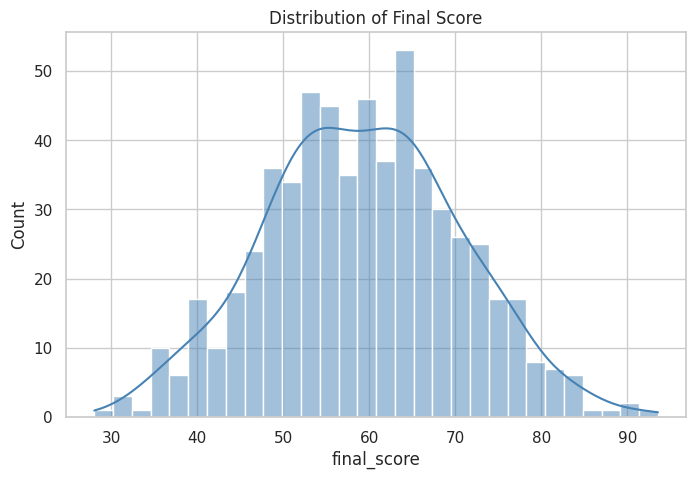

In [5]:
plt.figure(figsize=(8,5))
sns.histplot(df['final_score'], kde=True, bins=30, color='steelblue')
plt.title('Distribution of Final Score')
plt.show()

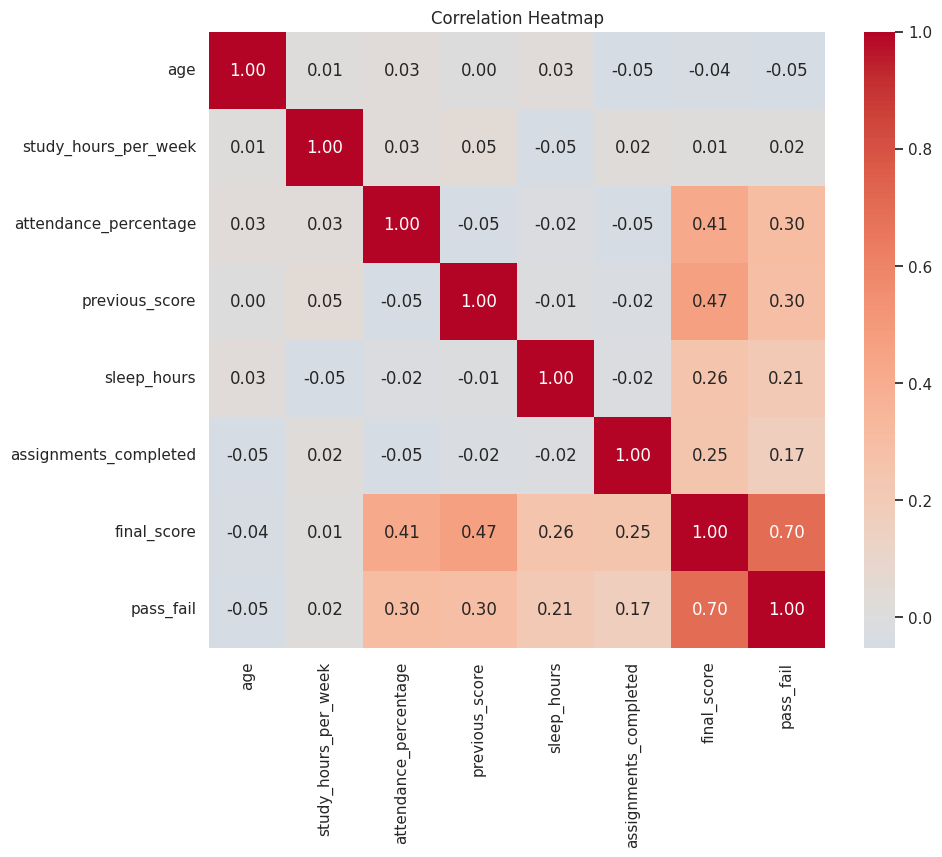

In [6]:
plt.figure(figsize=(10,8))
sns.heatmap(df.select_dtypes(include=[np.number]).drop(columns=['student_id']).corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation Heatmap')
plt.show()

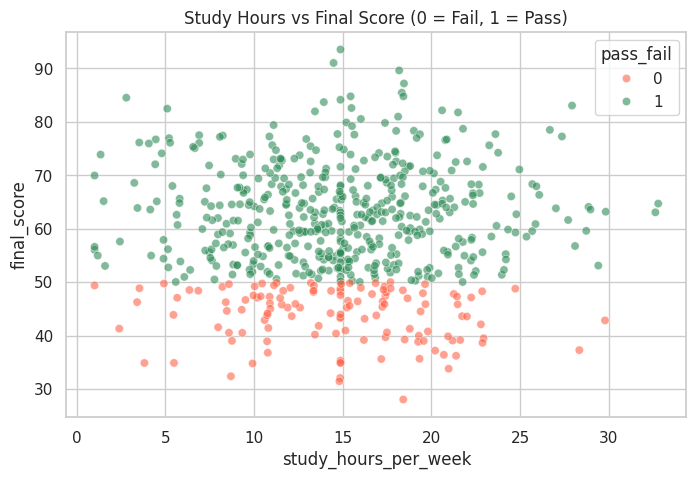

In [7]:
# Scatter plot example
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='study_hours_per_week', y='final_score', hue='pass_fail', palette={0:'tomato',1:'seagreen'}, alpha=0.6)
plt.title('Study Hours vs Final Score (0 = Fail, 1 = Pass)')
plt.show()

**My observations:** *(write 3-4 findings from the charts in your own words)*

## 5. Features and train/test split

In [8]:
X = df.drop(columns=['student_id','final_score','pass_fail'])
y = df['final_score']
num_features = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
cat_features = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (480, 11) Test: (120, 11)


## 6. Preprocessing, training and evaluation

In [9]:
preprocess = ColumnTransformer(transformers=[
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_features),
])
models = {'Linear Regression': LinearRegression(), 'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42)}
results, trained = {}, {}
for name, model in models.items():
    pipe = Pipeline([('preprocess', preprocess), ('model', model)])
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    results[name] = {'RMSE': np.sqrt(mean_squared_error(y_test, p)), 'MAE': mean_absolute_error(y_test, p), 'R2': r2_score(y_test, p)}
    trained[name] = pipe
pd.DataFrame(results).T.round(4)

,RMSE,MAE,R2
Linear Regression,5.4452,4.4089,0.7494
Random Forest,7.1550,5.8531,0.5673


## 7. Best model: actual vs predicted

Best model: Linear Regression


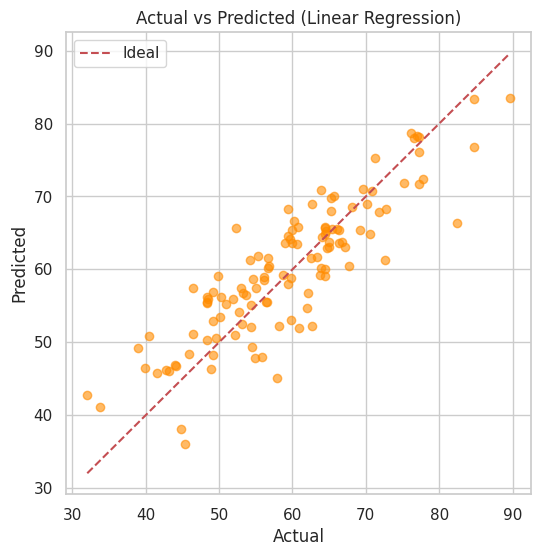

Pass/Fail accuracy: 0.8667


In [10]:
best_name = min(results, key=lambda k: results[k]['RMSE'])
best_model = trained[best_name]
preds = best_model.predict(X_test)
print('Best model:', best_name)

plt.figure(figsize=(6,6))
plt.scatter(y_test, preds, alpha=0.6, color='darkorange')
lims = [min(y_test.min(), preds.min()), max(y_test.max(), preds.max())]
plt.plot(lims, lims, 'r--', label='Ideal')
plt.xlabel('Actual'); plt.ylabel('Predicted'); plt.title(f'Actual vs Predicted ({best_name})')
plt.legend(); plt.show()

acc = accuracy_score((y_test>=50).astype(int), (preds>=50).astype(int))
print('Pass/Fail accuracy:', round(acc, 4))

## 8. Save the model and predict for a new student

In [11]:
joblib.dump(best_model, '../models/student_performance_model.pkl')
sample = pd.DataFrame([{'gender':'Female','age':18,'study_hours_per_week':20,'attendance_percentage':90,
    'previous_score':80,'sleep_hours':8,'assignments_completed':9,'extracurricular':'Yes',
    'parental_education':'Master','internet_access':'Yes','health_status':'Excellent'}])
score = float(best_model.predict(sample)[0])
print('Predicted score:', round(score, 2), '->', 'Pass' if score >= 50 else 'Fail')

Predicted score: 86.9 -> Pass


## 9. Conclusion

*(Write this yourself after running the notebook: which model was best, its R2 and RMSE, which features mattered most, and one limitation such as the data being synthetic.)*